# AVIPE signal model

A plain Python version of the signal chain in the [proposal](../docs/proposal.qmd)

mic → sum of 3 → DC removal → Ring Buffer → FFT → Hamming window and magnitude → display bars and peak frequency

## Inputs

In [ ]:
# ---- input ----
SOURCE      = 'wav'        # 'tone', 'chirp', 'wav', or 'mic' (mic also runs the live display at the end)
TONE_HZ     = 1000          # tone frequency, Hz
AMPLITUDE   = 4000          # tone, chirp and wav peak, in mic LSBs
DC_OFFSET   = -3000         # mic DC offset, in mic LSBs
NOISE_LSB   = 400           # rms white noise, in mic LSBs
CHIRP_F0, CHIRP_F1 = 1000, 2000
WAV_PATH    = 'input.wav'
MIC_DEVICE  = None          # None = system default
MIC_GAIN    = 1 / 16        # scales the mic down
LIVE_SECONDS = 10
WINDOW_TYPE = 'hamming'     # 'hanning', 'hamming', or 'none'

# ---- design ----
MIC_RATE      = 46_875      # Hz: BCLK 3 MHz / 64
MIC_BITS      = 18
SUM_N         = 2           # samples added per output sample
AVERAGE_SHIFT = 8           # DC removal: running average weight 2^-AVERAGE_SHIFT
FRAME_N       = 512         # FFT points
HOP_MS        = 20          # a new FFT every HOP_MS
N_FRAMES      = 12          # frames to simulate

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from IPython.display import display

plt.rcParams.update({'figure.figsize': (11, 3.4), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

FS     = MIC_RATE / SUM_N                       # sample rate after the sum
HOP    = min(FRAME_N, round(FS * HOP_MS / 1000))  # samples between FFTs, at most one frame
BIN_HZ = FS / FRAME_N
N_OUT  = FRAME_N + HOP * (N_FRAMES - 1)         # samples to simulate
MIC_FS = 2 ** (MIC_BITS - 1)                    # full scale of each block's samples
SUM_FS = 2 ** (MIC_BITS + 1)                    # 20 bits after the sum
PCM_FS = 2 ** 15                                # 16 bits after DC removal

def table(rows, cols=('value',)):
    display(pd.DataFrame(rows, columns=['', *cols]).set_index(''))

table([('sample rate', f'{FS/1e3:.3f} kHz'), ('frame', f'{FRAME_N} samples = {FRAME_N/FS*1e3:.1f} ms'),
       ('hop', f'{HOP} samples = {HOP/FS*1e3:.1f} ms'), ('overlap', f'{FRAME_N - HOP} samples ({(FRAME_N - HOP)/FRAME_N:.0%})'), ('bin width', f'{BIN_HZ:.1f} Hz'),
       ('highest frequency', f'{FS/2/1e3:.2f} kHz'), ('display bars', f'{FRAME_N//2 - 2} (bins 1 to {FRAME_N//2 - 2})')])

,value
,
sample rate,23.438 kHz
frame,512 samples = 21.8 ms
hop,469 samples = 20.0 ms
overlap,43 samples (8%)
bin width,45.8 Hz
highest frequency,11.72 kHz
display bars,254 (bins 1 to 254)


## 1. Microphone
The input, as 18-bit samples at 46.875 kHz.

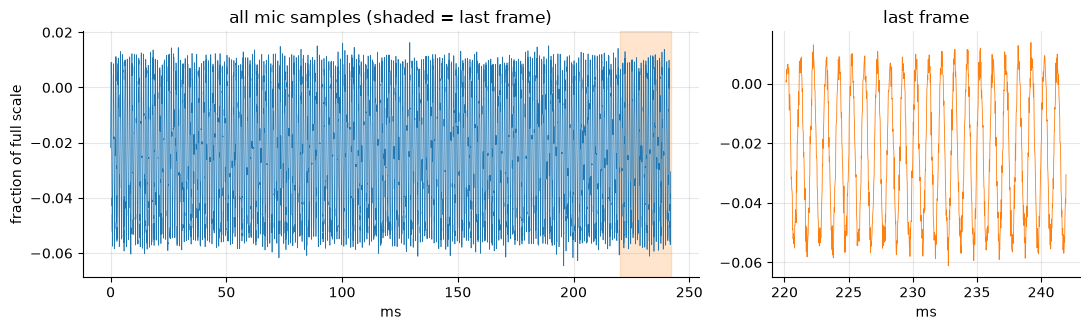

In [103]:
def microphone(n):
    t = np.arange(n) / MIC_RATE
    if SOURCE == 'tone':
        s = AMPLITUDE * np.sin(2 * np.pi * TONE_HZ * t)
    elif SOURCE == 'chirp':
        s = AMPLITUDE * np.sin(2 * np.pi * (CHIRP_F0 * t + (CHIRP_F1 - CHIRP_F0) * t ** 2 / (2 * t[-1])))
    elif SOURCE == 'wav':
        from scipy.io import wavfile
        from scipy.signal import resample
        rate, w = wavfile.read(WAV_PATH)
        w = w.mean(axis=1) if w.ndim > 1 else w.astype(float)
        w = resample(w, int(len(w) * MIC_RATE / rate))
        return np.round(np.resize(w / np.abs(w).max() * AMPLITUDE, n))
    elif SOURCE == 'mic':
        import sounddevice as sd
        r = sd.rec(n, samplerate=MIC_RATE, channels=1, device=MIC_DEVICE); sd.wait()
        return np.round(r[:, 0] * MIC_GAIN * MIC_FS)
    else:
        raise ValueError(f'unknown SOURCE {SOURCE!r}')
    s += DC_OFFSET + np.random.default_rng(1).normal(0, NOISE_LSB, n)
    return np.clip(np.round(s), -MIC_FS, MIC_FS - 1)             # 18-bit integers

x = microphone(N_OUT * SUM_N)

t_mic = np.arange(len(x)) / MIC_RATE * 1e3
last = slice(len(x) - FRAME_N * SUM_N, len(x))
fig, ax = plt.subplots(1, 2, gridspec_kw={'width_ratios': [2, 1]})
ax[0].plot(t_mic, x / MIC_FS, lw=0.5)
ax[0].axvspan(t_mic[last][0], t_mic[last][-1], color='C1', alpha=0.2)
ax[0].set(title='all mic samples (shaded = last frame)', xlabel='ms', ylabel='fraction of full scale')
ax[1].plot(t_mic[last], x[last] / MIC_FS, lw=0.6, color='C1')
ax[1].set(title='last frame', xlabel='ms')
plt.tight_layout(); plt.show()

## 2. Sample Sum
Adds mic samples so the rate drops. 

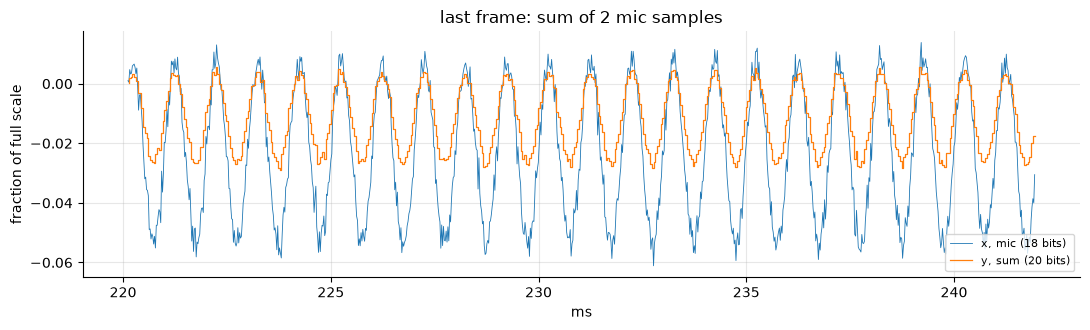

In [104]:
y = x.reshape(-1, SUM_N).sum(axis=1)

fig, ax = plt.subplots()
ax.plot(t_mic[last], x[last] / MIC_FS, lw=0.6, label='x, mic (18 bits)')
ax.step(t_mic[last][SUM_N - 1::SUM_N], y[-FRAME_N:] / SUM_FS, where='pre', lw=0.9, color='C1', label='y, sum (20 bits)')
ax.set(title='last frame: sum of '+str(SUM_N)+' mic samples', xlabel='ms', ylabel='fraction of full scale'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. DC removal
Subtracts a slow running average $\mu$ and keeps the lower 16 bits, saturating: $p = \mathrm{clip}_{16}(y - \mu)$. Dropping the top 4 bits makes the signal 16 times bigger relative to full scale (the gain in the proposal), so loud sounds clip at ±1.

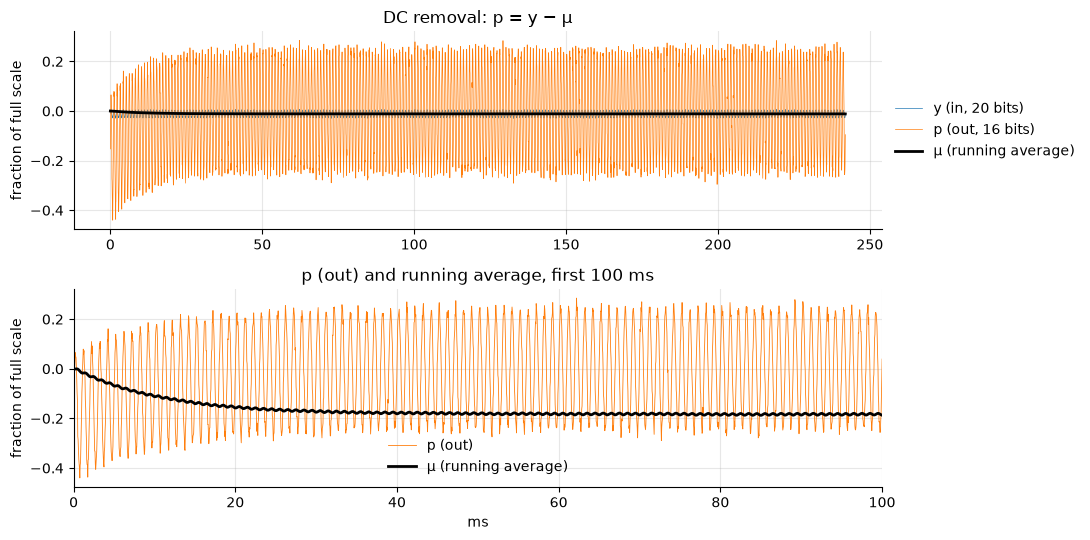

In [105]:
a = 2.0 ** -AVERAGE_SHIFT
mu = lfilter([0, a], [1, -(1 - a)], y)               # mu[n+1] = mu[n] + a (y[n] - mu[n])
p = np.clip(y - mu, -PCM_FS, PCM_FS - 1)

t = np.arange(len(y)) / FS * 1e3
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5))
ax[0].plot(t, y / SUM_FS, lw=0.5, label='y (in, 20 bits)')
ax[0].plot(t, p / PCM_FS, lw=0.5, label='p (out, 16 bits)')
ax[0].plot(t, mu / SUM_FS, 'k', lw=2, label='μ (running average)')
ax[0].set(title='DC removal: p = y − μ', ylabel='fraction of full scale'); ax[0].legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax[1].plot(t, p / PCM_FS, lw=0.6, color='C1', label='p (out)')
ax[1].plot(t, mu / PCM_FS, 'k', lw=2, label='μ (running average)')
ax[1].set(title='p (out) and running average, first 100 ms', xlabel='ms', ylabel='fraction of full scale', xlim=(0, 100))
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Frames
Every `HOP` samples, the latest `FRAME_N` samples become one frame, so neighbouring frames overlap by `FRAME_N − HOP` samples.

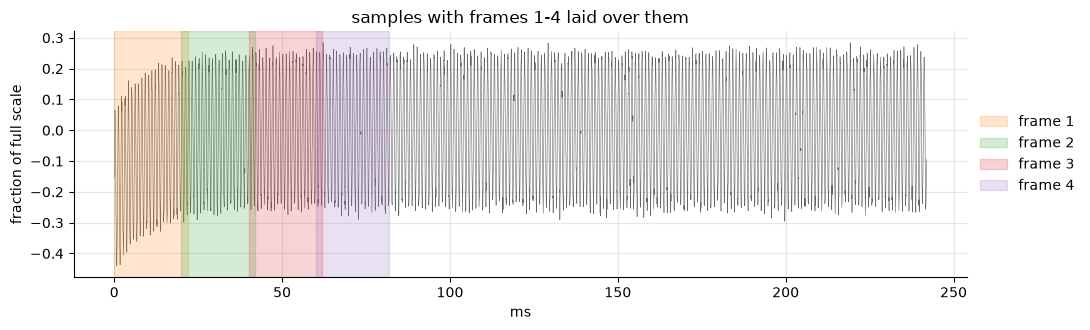

In [106]:
starts = HOP * np.arange(N_FRAMES)
frames = [p[s:s + FRAME_N] for s in starts]

fig, ax = plt.subplots()
ax.plot(t, p / PCM_FS, lw=0.4, color='0.4')
for k in range(min(4, N_FRAMES)):
    ax.axvspan(starts[k] / FS * 1e3, (starts[k] + FRAME_N) / FS * 1e3, color=f'C{k+1}', alpha=0.2, zorder=3, label=f'frame {k+1}')
ax.set(title='samples with frames 1-4 laid over them', xlabel='ms', ylabel='fraction of full scale')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout(); plt.show()

## 5. FFT, window and magnitude
Apply the selected window function to the last frame, take the FFT, and keep the magnitude of bins 1 to 254 in dBFS. The peak is the largest bin.

In [107]:
def spectrum(frame):
    window_type = WINDOW_TYPE.lower()
    if window_type in ('hann', 'hanning'):
        window = np.hanning(FRAME_N)
    elif window_type == 'hamming':
        window = np.hamming(FRAME_N)
    elif window_type == 'none':
        window = np.ones(FRAME_N)
    else:
        raise ValueError(f'unknown window type {WINDOW_TYPE!r}; choose hanning, hamming, or none')

    X = np.fft.rfft(frame * window)
    k = np.arange(1, FRAME_N // 2 - 1)
    window_gain = window.sum() / 2
    db = 20 * np.log10(np.maximum(np.abs(X[k]), 1e-9) / (PCM_FS * window_gain))   # 0 dBFS = full-scale sine
    return k * BIN_HZ, db, k[np.argmax(db)] * BIN_HZ

freqs, db, peak_hz = spectrum(frames[-1])
rows = [('peak', f'{peak_hz:.0f} Hz at {db.max():.1f} dBFS')]
if SOURCE == 'tone':
    rows.append(('tone', f'{TONE_HZ} Hz (peak is {abs(peak_hz - TONE_HZ):.0f} Hz away, bins are {BIN_HZ:.1f} Hz)'))
table(rows)

,value
,
peak,1007 Hz at -12.4 dBFS
tone,"1000 Hz (peak is 7 Hz away, bins are 45.8 Hz)"


## Display

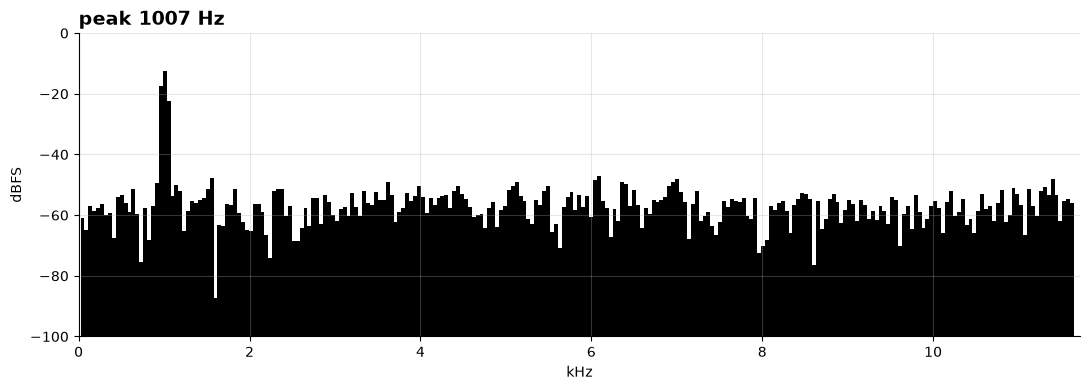

In [108]:
FLOOR_DB = -100                                     # bottom of the display

def draw_display(ax, freqs, db, peak_hz):
    bars = ax.bar(freqs / 1e3, np.maximum(db, FLOOR_DB) - FLOOR_DB, bottom=FLOOR_DB, width=BIN_HZ / 1e3, color='k')
    ax.set(xlim=(0, FS / 2 / 1e3), ylim=(FLOOR_DB, 0), xlabel='kHz', ylabel='dBFS')
    ax.set_title(f'peak {peak_hz:.0f} Hz', loc='left', fontsize=14, fontweight='bold')
    return bars

fig, ax = plt.subplots(figsize=(11, 4))
draw_display(ax, freqs, db, peak_hz)
plt.tight_layout(); plt.show()

## 7. Live microphone
Runs the same steps on your microphone every hop and redraws the display. Only runs when `SOURCE = 'mic'`; press interrupt to stop early.

In [109]:
def live(seconds):
    import queue, time
    import sounddevice as sd
    q = queue.Queue(maxsize=100)
    lost = {'overflow': 0, 'dropped': 0}
    def on_audio(indata, n, t_info, status):
        if status.input_overflow: lost['overflow'] += 1              # audio the computer never delivered
        try: q.put_nowait(indata[:, 0].copy())
        except queue.Full: lost['dropped'] += 1

    ring, zi, hops, drawn, clipped = np.zeros(FRAME_N), np.zeros(1), 0, 0, 0
    fig, ax = plt.subplots(figsize=(11, 4))
    bars = draw_display(ax, np.arange(1, FRAME_N // 2 - 1) * BIN_HZ, np.full(FRAME_N // 2 - 2, FLOOR_DB), 0)
    plt.tight_layout()
    handle = display(fig, display_id=True); plt.close(fig)
    end = time.time() + seconds
    try:
        with sd.InputStream(samplerate=MIC_RATE, blocksize=HOP * SUM_N, channels=1, latency=0.5,
                            device=MIC_DEVICE, callback=on_audio):        # big buffer so redraws don't lose audio
            while time.time() < end:
                try: block = q.get(timeout=1)
                except queue.Empty: continue
                y_b = np.round(block * MIC_GAIN * MIC_FS).reshape(-1, SUM_N).sum(axis=1)       # sum of 3
                mu_b, zi = lfilter([0, a], [1, -(1 - a)], y_b, zi=zi)              # DC removal
                d_b = y_b - mu_b
                clipped += int(np.sum(np.abs(d_b) >= PCM_FS))                      # samples past 16 bits
                ring = np.concatenate([ring[HOP:], np.clip(d_b, -PCM_FS, PCM_FS - 1)])
                hops += 1
                if hops * HOP < FRAME_N or time.time() - drawn < 0.1 or not q.empty():
                    continue                                                       # redraw at most 10x a second
                drawn = time.time()
                f, m, pk = spectrum(ring)
                for bar, h in zip(bars, np.maximum(m, FLOOR_DB) - FLOOR_DB):
                    bar.set_height(h)
                ax.set_title(f'peak {pk:.0f} Hz', loc='left', fontsize=14, fontweight='bold')
                clip_now = np.mean(np.abs(ring) >= PCM_FS - 1)
                ax.set_title(f'CLIPPING ({clip_now:.0%} of frame)' if clip_now else '', loc='right', color='C3')
                handle.update(fig)
    except KeyboardInterrupt:
        pass
    print(f'stopped after {hops * HOP / FS:.1f} s of audio; clipped samples: {clipped}, '
          f'overflows: {lost["overflow"]}, dropped blocks: {lost["dropped"]}')

if SOURCE == 'mic' and LIVE_SECONDS > 0:
    live(LIVE_SECONDS)
else:
    print("Set SOURCE = 'mic' in the Inputs cell to run the live display.")

Set SOURCE = 'mic' in the Inputs cell to run the live display.
